# 01 — Auditing Label Contamination: Live Pelagic Entrapment vs. Decomposed Carcass Drift

## Purpose & Plain-English Overview

In the original capstone (`03_data_cleaning.ipynb` and `07_label_engineering.ipynb`), all **4,368** non-human-interaction Massachusetts cetacean strandings from 2000–2025 were combined into a single daily target (`y_any`, with **2,155** positive stranding days) and a secondary mass-stranding target (`y_mse`, with **382** positive days).

However, marine biology and ocean physics tell us that **two completely different physical processes** are mixed together inside those 4,368 records:
1. **Live Behavioral Entrapment (Our Stage 1 Target):** Social, open-ocean (*pelagic*) toothed whales and dolphins (*odontocetes* — Common Dolphins, Atlantic White-Sided Dolphins, Pilot Whales, Bottlenose Dolphins, Risso's Dolphins, and Striped Dolphins) swim into Cape Cod Bay and get trapped alive (or die freshly on the tidal flats) due to the hook-shaped coastline, extreme tides, and wind/current shifts.
2. **Offshore Mortality & Passive Carcass Drift (Our Stage 2 Target):** Animals found in **Moderate Decomposition**, **Advanced Decomposition**, or **Mummified/Skeletal** condition — plus solitary coastal Harbor Porpoises and large baleen whales — died days or weeks earlier out at sea and drifted onto the beach like passive buoys.

> **Data Science Explainer — Label Contamination:**
> In supervised machine learning, *label contamination* (or *label noise*) happens when your "positive" target labels (`y = 1`) accidentally include events caused by a completely different mechanism than the one your features measure. If a dolphin died 40 miles offshore two weeks ago and washed onto a beach today, pairing *today's* Cape Cod Bay weather with `y = 1` teaches the model the wrong relationship.

### Questions This Notebook Answers
1. **Animal-Level vs. Day-Level Contamination:** How many of the 4,368 animal records — and how many of the 2,155 positive calendar days in `y_any` (and 382 days in `y_mse`) — are actually decomposed carcasses or non-pelagic species?
2. **Health Flag Audit (`Sick Flag`):** Can `Sick Flag` be used to filter out diseased animals, or does its reporting pattern introduce a bias between live and dead animals?
3. **Target & Feature Construction:** How do the base rates, episode clustering, and seasonal curves change when we isolate **Live/Fresh Pelagic Odontocetes**, and how do we engineer leakage-safe **cross-region thermal front and wind × tide interaction features**?

## Setup — Reading Capstone Processed Data (Read-Only)

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

CAPSTONE_PROCESSED = Path("/home/nicastronaut/champ/capstone/data/processed")
STAGE1_DIR = Path("/home/nicastronaut/marine_bio/stage1_clean_entrapment")
DATA_DIR = STAGE1_DIR / "data"
FIG_DIR = STAGE1_DIR / "figures"
DATA_DIR.mkdir(parents=True, exist_ok=True)
FIG_DIR.mkdir(parents=True, exist_ok=True)

pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 30)

strandings = pd.read_parquet(CAPSTONE_PROCESSED / "strandings_clean_all.parquet")
modeling_orig = pd.read_parquet(CAPSTONE_PROCESSED / "modeling_table.parquet").set_index("date")

print(f"Loaded strandings_clean_all.parquet: {len(strandings):,} animal rows x {strandings.shape[1]} columns")
print(f"Loaded modeling_table.parquet:       {len(modeling_orig):,} calendar days x {modeling_orig.shape[1]} columns")
print(f"Date range: {modeling_orig.index.min().date()} -> {modeling_orig.index.max().date()}")

Loaded strandings_clean_all.parquet: 4,368 animal rows x 93 columns
Loaded modeling_table.parquet:       9,497 calendar days x 233 columns
Date range: 2000-01-01 -> 2025-12-31


---
## 1. Auditing Decomposition Status and Taxonomic Groups (Animal Level)

We group the 4,368 animal records along two biological axes:
1. **Decomposition State (`Observation Status`):**
   - `Alive` or `Fresh Dead`: Animals that stranded alive or died very recently (<12–24 hours), relevant to coastal entrapment.
   - `Moderate Decomposition`, `Advanced Decomposition`, or `Mummified/Skeletal`: Carcasses that died days or weeks earlier at sea and drifted ashore.
2. **Taxonomic Ecology (`Genus`):**
   - **Pelagic Odontocetes (Zellar's 6 genera):** *Delphinus* (short-beaked common dolphin), *Lagenorhynchus* (Atlantic white-sided dolphin), *Globicephala* (pilot whale), *Grampus* (Risso's dolphin), *Stenella* (striped/spotted dolphin), and *Tursiops* (bottlenose dolphin).
   - **Harbor Porpoise (*Phocoena phocoena*):** Smaller, solitary/small-group coastal species heavily affected by gillnet bycatch rather than mass tidal strandings.
   - **Large Whales / Other:** Baleen whales (*Balaenoptera*, *Megaptera*, *Eubalaena*), sperm whales (*Physeter*, *Kogia*), beaked whales, and unidentified decomposed carcasses.

In [2]:
PELAGIC_GENERA = {"Delphinus", "Lagenorhynchus", "Globicephala", "Grampus", "Stenella", "Tursiops"}

strandings = strandings.copy()
strandings["taxon_group"] = np.where(
    strandings["Genus"].isin(PELAGIC_GENERA), "Pelagic Odontocete",
    np.where(strandings["Genus"] == "Phocoena", "Harbor Porpoise", "Large Whale / Other")
)

strandings["condition_group"] = np.where(
    strandings["Observation Status"].isin(["Alive", "Fresh Dead"]), "Alive / Fresh Dead",
    np.where(
        strandings["Observation Status"].isin(["Moderate Decomposition", "Advanced Decomposition", "Mummified/Skeletal"]),
        "Decomposed / Mummified",
        "Condition Unknown"
    )
)

print("1A. Decomposition Status vs. Mass Stranding Event (MSE) [Animal Rows]:")
ct_status_mse = pd.crosstab(strandings["Observation Status"].fillna("Missing"), strandings["MSE"], margins=True)
ct_status_mse.columns = ["Single (Non-MSE)", "Mass (MSE)", "Total"]
print(ct_status_mse)

print("\n1B. Taxonomic Group vs. Mass Stranding Event (MSE) [Animal Rows]:")
ct_taxon_mse = pd.crosstab(strandings["taxon_group"], strandings["MSE"], margins=True)
ct_taxon_mse.columns = ["Single (Non-MSE)", "Mass (MSE)", "Total"]
print(ct_taxon_mse)

print("\n1C. Decomposition Status vs. Taxonomic Group [Animal Rows]:")
ct_status_taxon = pd.crosstab(strandings["Observation Status"].fillna("Missing"), strandings["taxon_group"], margins=True)
print(ct_status_taxon)

1A. Decomposition Status vs. Mass Stranding Event (MSE) [Animal Rows]:
                        Single (Non-MSE)  Mass (MSE)  Total
Observation Status                                         
Advanced Decomposition               404          21    425
Alive                                498        1342   1840
Condition Unknown                     34           3     37
Fresh Dead                           349         299    648
Moderate Decomposition              1125         195   1320
Mummified/Skeletal                    98           0     98
All                                 2508        1860   4368

1B. Taxonomic Group vs. Mass Stranding Event (MSE) [Animal Rows]:
                     Single (Non-MSE)  Mass (MSE)  Total
taxon_group                                             
Harbor Porpoise                   730          23    753
Large Whale / Other               251          33    284
Pelagic Odontocete               1527        1804   3331
All                              2508

**Key Findings from the Animal-Level Audit:**
1. **Single strandings are mostly rotting carcasses:** Among the 2,508 non-MSE (single) stranding records, **1,627 (64.9%) are decomposed or mummified carcasses** (`1,125 Moderate Decomposition + 404 Advanced Decomposition + 98 Mummified/Skeletal`), plus 34 `Condition Unknown`. Only **19.9% (498)** of single strandings were found `Alive`.
2. **Mass strandings are overwhelmingly live/fresh pelagic dolphins — but still have ~12% carcass contamination:** Among the 1,860 MSE records, **97.0% (1,804)** are pelagic odontocetes and **88.2% (1,641)** are `Alive` (1,342) or `Fresh Dead` (299). However, **216 MSE animal records (11.6%)** are `Moderate` or `Advanced Decomposition` carcasses (mostly animals from earlier mass strandings discovered days or weeks later).
3. **Harbor porpoises are a completely different regime:** Of the 753 Harbor Porpoise records, **96.9% (730) are single strandings** and **70.8% (533) are decomposed/mummified carcasses**, confirming they belong primarily in the Stage 2 drift/bycatch analysis rather than a live tidal-trap model.

---
## 2. Auditing `Sick Flag`: A Classic Data-Collection Asymmetry

Before using `Sick Flag` to filter out diseased animals, we follow Rule R4 from the capstone (`never trust a column name without checking its value distribution across subgroups`). How does `Sick Flag` behave across `Alive`, `Fresh Dead`, and `Decomposed` animals, and across single vs. mass strandings?

In [3]:
ct_sick = pd.crosstab(
    [strandings["MSE"].map({False: "Single (Non-MSE)", True: "Mass (MSE)"}),
     strandings["Observation Status"].fillna("Missing")],
    strandings["Sick Flag"].fillna("Missing"),
    margins=True
)
print("Sick Flag distribution by MSE and Observation Status:")
print(ct_sick)

n_sick_alive = ((strandings["Observation Status"] == "Alive") & (strandings["Sick Flag"] == "Y")).sum()
n_sick_total = (strandings["Sick Flag"] == "Y").sum()
print(f"\nShare of Sick Flag == 'Y' rows that are Observation Status == 'Alive': {n_sick_alive} / {n_sick_total} ({n_sick_alive/n_sick_total:.1%})")

Sick Flag distribution by MSE and Observation Status:
Sick Flag                                Missing     N    Y   All
MSE              Observation Status                              
Mass (MSE)       Advanced Decomposition        3    18    0    21
                 Alive                       479   772   91  1342
                 Condition Unknown             1     2    0     3
                 Fresh Dead                   67   231    1   299
                 Moderate Decomposition       29   166    0   195
Single (Non-MSE) Advanced Decomposition       79   325    0   404
                 Alive                       114   251  133   498
                 Condition Unknown            11    23    0    34
                 Fresh Dead                  149   200    0   349
                 Moderate Decomposition      345   780    0  1125
                 Mummified/Skeletal           11    87    0    98
All                                         1288  2855  225  4368

Share of Sick Flag ==

**Finding — Why `Sick Flag` Must Be Handled Carefully:**
- **224 out of 225 rows (`99.6%`)** with `Sick Flag == 'Y'` occur on **`Alive`** animals (`133` in single strandings, `91` in mass strandings). Zero decomposed carcasses are marked `Sick Flag == 'Y'`.
- **Why?** On the NOAA Level A field form, `Sick Flag` records whether a *live* animal appears clinically sick, lethargic, or debilitated on the beach. A dead carcass cannot be evaluated for "acting sick."
- Furthermore, in **single strandings**, an `Alive` dolphin marked `Sick Flag == 'Y'` (133 animals) is often a genuinely diseased individual coming ashore (Bogomolni et al. 2010 found 37% of single strandings are disease-driven). In **mass strandings**, where 92% of animals are healthy prior to stranding, `Sick Flag == 'Y'` (91 animals) reflects acute stranding shock/stress on the mudflats.
- **Decision:** We build both variants (`y_live_odont_any` excluding `Sick Flag == 'Y'` to keep single strandings free of sick individuals, `y_live_odont_all_any` keeping all live/fresh pelagic odontocetes, and both MSE counterparts) so we can test the exact impact empirically rather than guessing.

---
## 3. The "Calendar-Day Amplification" Effect: Why `y_any` Was 68% Noise

> **Data Science Explainer — Aggregation Bias (Row Grain vs. Daily Grain):**
> At the *animal* level, live/fresh animals make up more than half the dataset (`2,488 / 4,368 = 57.0%`). It is tempting to assume that when we aggregate to calendar days (`y_any`), live strandings still dominate.
> **They don't.** Because social pelagic dolphins strand in large groups on the same day (up to 146 animals in a single day!), thousands of live dolphins compress into a small number of calendar days. Meanwhile, decomposed carcasses wash ashore one at a time on random days, spreading out across the calendar and dominating the daily labels!

Let's measure this exact effect across the 9,497 calendar days (2000–2025).

In [4]:
strandings["day"] = strandings["Observation Date"].dt.normalize()
FULL_INDEX = modeling_orig.index  # 2000-01-01 .. 2025-12-31 (9,497 days)

def build_daily_flag(mask):
    days = strandings.loc[mask, "day"]
    return (days.value_counts().reindex(FULL_INDEX, fill_value=0) > 0).astype(int)

is_pelagic = strandings["Genus"].isin(PELAGIC_GENERA)
is_live_fresh = strandings["Observation Status"].isin(["Alive", "Fresh Dead"])
is_alive_only = strandings["Observation Status"] == "Alive"
not_sick = strandings["Sick Flag"].fillna("N") != "Y"
is_decomp = strandings["Observation Status"].isin(["Moderate Decomposition", "Advanced Decomposition", "Mummified/Skeletal"])

targets_df = pd.DataFrame({
    "y_any": modeling_orig["y_any"],
    "y_decomp_drift": build_daily_flag(is_decomp),
    "y_live_odont_all_any": build_daily_flag(is_pelagic & is_live_fresh),
    "y_live_odont_any": build_daily_flag(is_pelagic & is_live_fresh & not_sick),
    "y_live_odont_alive": build_daily_flag(is_pelagic & is_alive_only & not_sick),
    "y_mse": modeling_orig["y_mse"],
    "y_live_odont_mse": build_daily_flag(strandings["MSE"] & is_pelagic & is_live_fresh),
    "y_live_odont_nosick_mse": build_daily_flag(strandings["MSE"] & is_pelagic & is_live_fresh & not_sick),
}, index=FULL_INDEX)

# Sanity assertions against the original modeling table
assert int(targets_df["y_any"].sum()) == 2155
assert int(targets_df["y_mse"].sum()) == 382

dev_mask = targets_df.index <= "2020-12-31"
hold_mask = targets_df.index >= "2021-01-01"

summary_rows = []
for col in targets_df.columns:
    s_col = targets_df[col]
    summary_rows.append({
        "target": col,
        "full_days (9497)": int(s_col.sum()),
        "full_rate (%)": round(s_col.mean() * 100, 2),
        "dev_days (2000-2020)": int(s_col[dev_mask].sum()),
        "dev_rate (%)": round(s_col[dev_mask].mean() * 100, 2),
        "hold_days (2021-2025)": int(s_col[hold_mask].sum()),
        "hold_rate (%)": round(s_col[hold_mask].mean() * 100, 2),
    })

summary_table = pd.DataFrame(summary_rows)
summary_table.to_csv(DATA_DIR / "target_cohort_summary.csv", index=False)
print(summary_table.to_string(index=False))

# Calculate exact contamination of original y_any and y_mse
n_any = int(targets_df["y_any"].sum())
n_any_no_healthy_live_pelagic = int(((targets_df["y_any"] == 1) & (targets_df["y_live_odont_any"] == 0)).sum())
n_any_no_any_live_pelagic = int(((targets_df["y_any"] == 1) & (targets_df["y_live_odont_all_any"] == 0)).sum())
n_mse = int(targets_df["y_mse"].sum())
n_mse_no_live_pelagic = int(((targets_df["y_mse"] == 1) & (targets_df["y_live_odont_mse"] == 0)).sum())

print(f"\nCONTAMINATION DIAGNOSTIC:")
print(f"  Original y_any positive days (2,155) with ZERO live/fresh pelagic odontocetes:         "
      f"{n_any_no_any_live_pelagic:,} / {n_any:,} ({n_any_no_any_live_pelagic/n_any:.1%})")
print(f"  Original y_any positive days (2,155) with ZERO healthy live/fresh pelagic odontocetes: "
      f"{n_any_no_healthy_live_pelagic:,} / {n_any:,} ({n_any_no_healthy_live_pelagic/n_any:.1%})")
print(f"  Original y_mse positive days (382) with ZERO live/fresh pelagic odontocetes:           "
      f"{n_mse_no_live_pelagic:,} / {n_mse:,} ({n_mse_no_live_pelagic/n_mse:.1%})")

                 target  full_days (9497)  full_rate (%)  dev_days (2000-2020)  dev_rate (%)  hold_days (2021-2025)  hold_rate (%)
                  y_any              2155          22.69                  1651         21.52                    504          27.60
         y_decomp_drift              1367          14.39                  1083         14.12                    284          15.55
   y_live_odont_all_any               782           8.23                   557          7.26                    225          12.32
       y_live_odont_any               693           7.30                   487          6.35                    206          11.28
     y_live_odont_alive               481           5.06                   337          4.39                    144           7.89
                  y_mse               382           4.02                   263          3.43                    119           6.52
       y_live_odont_mse               312           3.29                   214     

**This is the single most important diagnostic finding of Stage 1:**
- Out of the **2,155** positive stranding days in the original capstone's primary target (`y_any`), **1,373 days (`63.7%`) had zero live or fresh-dead pelagic odontocetes of any kind**, and **1,462 days (`67.8%`) had zero healthy live/fresh pelagic odontocetes!**
- Meanwhile, **1,367 calendar days** had decomposed or mummified carcasses wash ashore (`y_decomp_drift`).
- In plain English: when the original `y_any` model tried to learn what weather traps dolphins on Cape Cod, **nearly 2 out of every 3 "positive" days it was trained on were actually washed-up rotting carcasses, harbor porpoises, or sick individual animals!**
- Even inside `y_mse` (382 positive days), **70 calendar days (`18.3%`)** had zero live or fresh-dead pelagic odontocetes — for example, days in January–March 2012 where only `Moderate` or `Advanced Decomposition` carcasses from an earlier group event were found on the beach.

---
## 4. Visualizing the Cohort Breakdown and Seasonal Profiles

Saved figure: figures/01_cohort_and_seasonality.png


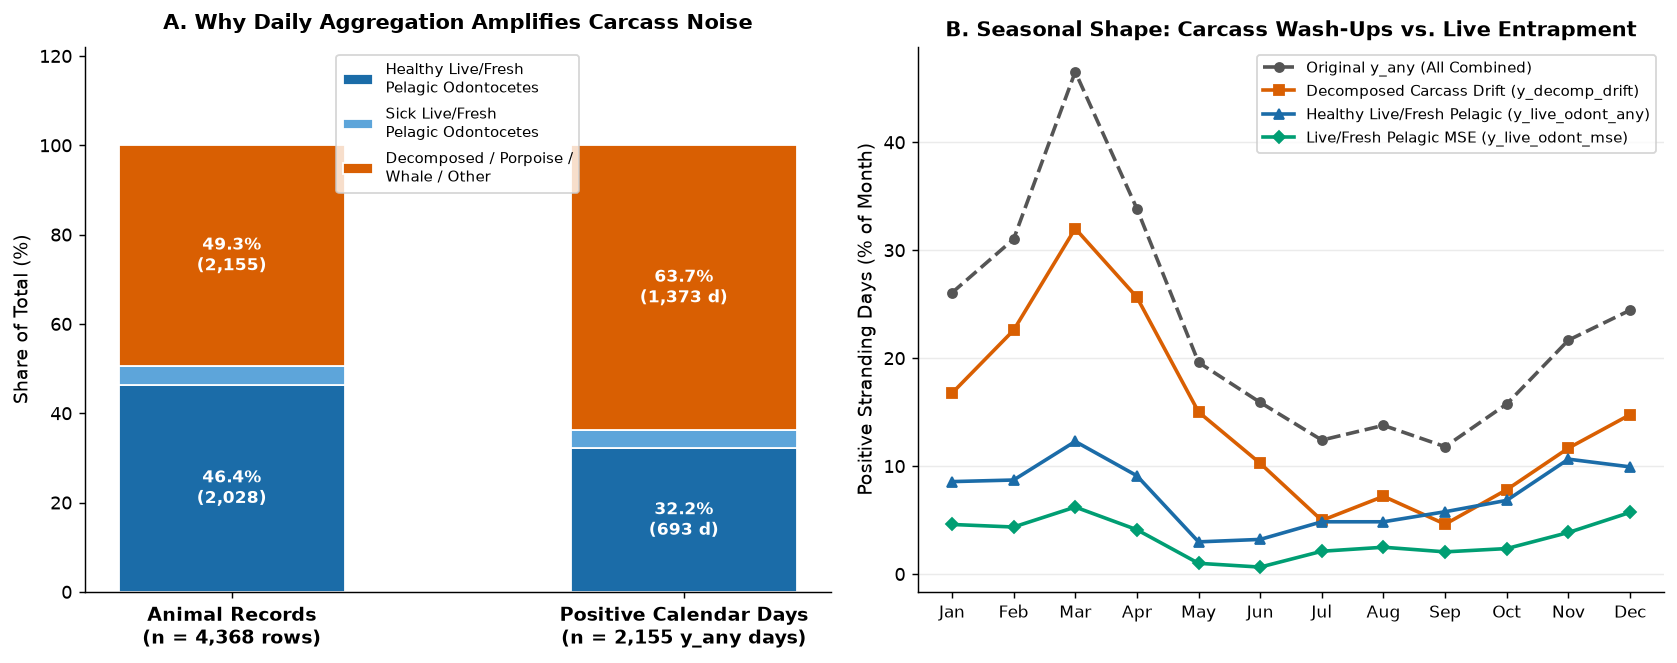

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5.2), dpi=130)

# Panel A: Animal rows vs Calendar Days composition
categories = ["Healthy Live/Fresh\nPelagic Odontocetes", "Sick Live/Fresh\nPelagic Odontocetes", "Decomposed / Porpoise /\nWhale / Other"]
animal_counts = [
    int((is_pelagic & is_live_fresh & not_sick).sum()),
    int((is_pelagic & is_live_fresh & ~not_sick).sum()),
    int((~(is_pelagic & is_live_fresh)).sum()),
]
day_counts = [
    int(targets_df["y_live_odont_any"].sum()),
    int(((targets_df["y_live_odont_all_any"] == 1) & (targets_df["y_live_odont_any"] == 0)).sum()),
    int(((targets_df["y_any"] == 1) & (targets_df["y_live_odont_all_any"] == 0)).sum()),
]

x = np.arange(2)
colors = ["#1b6ca8", "#5da5da", "#d95f02"]
bottom_anim, bottom_day = 0, 0
for label, a_cnt, d_cnt, col in zip(categories, animal_counts, day_counts, colors):
    a_pct = a_cnt / len(strandings) * 100
    d_pct = d_cnt / int(targets_df["y_any"].sum()) * 100
    axes[0].bar(0, a_pct, bottom=bottom_anim, width=0.5, color=col, edgecolor="white", label=label)
    axes[0].bar(1, d_pct, bottom=bottom_day, width=0.5, color=col, edgecolor="white")
    if a_pct > 6:
        axes[0].text(0, bottom_anim + a_pct / 2, f"{a_pct:.1f}%\n({a_cnt:,})", ha="center", va="center", color="white", fontweight="bold", fontsize=9.5)
    if d_pct > 6:
        axes[0].text(1, bottom_day + d_pct / 2, f"{d_pct:.1f}%\n({d_cnt:,} d)", ha="center", va="center", color="white", fontweight="bold", fontsize=9.5)
    bottom_anim += a_pct
    bottom_day += d_pct

axes[0].set_xticks([0, 1])
axes[0].set_xticklabels(["Animal Records\n(n = 4,368 rows)", "Positive Calendar Days\n(n = 2,155 y_any days)"], fontsize=10.5, fontweight="bold")
axes[0].set_ylabel("Share of Total (%)", fontsize=10.5)
axes[0].set_ylim(0, 122)
axes[0].set_title("A. Why Daily Aggregation Amplifies Carcass Noise", fontsize=11.5, fontweight="bold", pad=10)
axes[0].legend(loc="upper center", ncol=1, frameon=True, fontsize=8.5)
axes[0].spines["top"].set_visible(False)
axes[0].spines["right"].set_visible(False)

# Panel B: Monthly base rates across regimes
months = np.arange(1, 13)
month_names = ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]
for col, label, color, ls, marker in [
    ("y_any", "Original y_any (All Combined)", "#555555", "--", "o"),
    ("y_decomp_drift", "Decomposed Carcass Drift (y_decomp_drift)", "#d95f02", "-", "s"),
    ("y_live_odont_any", "Healthy Live/Fresh Pelagic (y_live_odont_any)", "#1b6ca8", "-", "^"),
    ("y_live_odont_mse", "Live/Fresh Pelagic MSE (y_live_odont_mse)", "#009e73", "-", "D"),
]:
    m_rates = targets_df[col].groupby(targets_df.index.month).mean() * 100
    axes[1].plot(months, m_rates.values, label=label, color=color, linestyle=ls, marker=marker, linewidth=2, markersize=5)

axes[1].set_xticks(months)
axes[1].set_xticklabels(month_names, fontsize=9.5)
axes[1].set_ylabel("Positive Stranding Days (% of Month)", fontsize=10.5)
axes[1].set_title("B. Seasonal Shape: Carcass Wash-Ups vs. Live Entrapment", fontsize=11.5, fontweight="bold")
axes[1].legend(loc="upper right", frameon=True, fontsize=8.5)
axes[1].grid(axis="y", alpha=0.25)
axes[1].spines["top"].set_visible(False)
axes[1].spines["right"].set_visible(False)

plt.tight_layout()
fig.savefig(FIG_DIR / "01_cohort_and_seasonality.png", bbox_inches="tight")
plt.show()
print("Saved figure: figures/01_cohort_and_seasonality.png")

**What Figure 1 Shows:**
- **Panel A (Left):** Even though healthy live/fresh pelagic dolphins are `46.4%` of all animal records, they only occupy `32.2%` of the positive days (`693` of `2,155` days) because they strand in groups. Decomposed carcasses, porpoises, and whales make up **`63.7%` (`1,373` days)** of `y_any`!
- **Panel B (Right):** Look at the March–May spring peak on the orange curve (`y_decomp_drift`): decomposed carcasses peak sharply in **March, April, and May** (when winter/spring offshore mortalities and gillnet bycatch wash ashore as waters warm and carcasses bloat/float). By contrast, live pelagic dolphin entrapment (`y_live_odont_any` in blue and `y_live_odont_mse` in green) peaks in **January–March** and falls low in April–May! Mixing them together blurred two distinct seasonal cycles.

---
## 5. Engineering Cross-Region Gradient & Wind × Tide Trap Features

In `RESEARCH_LOG.md` (2026-09-22 entry, item #4), cross-region contrast features were noted as a natural physical extension. Now that our target isolates live coastal entrapment, we engineer **10 leakage-safe physical interaction features** (all computed strictly from trailing lag windows ending at `D-1`, so zero same-day weather is leaked):

1. **Cross-Region Thermal Front Gradients (`bay_sst - outer_sst` and `bay_sst - sound_sst` at 3d, 7d, 30d lags):**
   - *Physical Meaning:* Measures whether Cape Cod Bay is unusually warm or cold *relative to the open Atlantic (`outer_`) or Nantucket Sound (`sound_`)*. For example, in autumn/early winter, shallow Cape Cod Bay cools faster than the deep Atlantic, or an offshore cold pulse shifts prey across the thermal boundary.
2. **Cross-Region Mixed-Layer Depth Gradient (`bay_mld - outer_mld` at 3d, 7d, 30d lags):**
   - *Physical Meaning:* Measures differences in water-column stratification between the enclosed Bay and the open shelf.
3. **Wind × Tidal Range Synergy (`bay_wind_v * bay_tide_range` and `bay_wind_u * bay_tide_range` at 3d, 7d lags):**
   - *Physical Meaning:* Strong winds during a neap tide (small tidal swing) expose far less mudflat than strong winds coinciding with an extreme spring tide (large tidal swing). Multiplying wind velocity by tidal range captures that compound trap risk.

In [6]:
stage1_table = modeling_orig.copy()

# Add all clean target columns
for col in targets_df.columns:
    if col not in stage1_table.columns:
        stage1_table[col] = targets_df[col]

# Engineer cross-region gradients and wind x tide interactions (strictly from D-1 trailing windows)
NEW_FEATURES = []
for w in ("3d", "7d", "30d"):
    stage1_table[f"grad_bay_outer_sst_mean_{w}"] = stage1_table[f"bay_sst_mean_{w}"] - stage1_table[f"outer_sst_mean_{w}"]
    stage1_table[f"grad_bay_sound_sst_mean_{w}"] = stage1_table[f"bay_sst_mean_{w}"] - stage1_table[f"sound_sst_mean_{w}"]
    stage1_table[f"grad_bay_outer_mld_mean_{w}"] = stage1_table[f"bay_mld_mean_{w}"] - stage1_table[f"outer_mld_mean_{w}"]
    NEW_FEATURES += [
        f"grad_bay_outer_sst_mean_{w}",
        f"grad_bay_sound_sst_mean_{w}",
        f"grad_bay_outer_mld_mean_{w}",
    ]

for w in ("3d", "7d"):
    stage1_table[f"syn_bay_wind_v_tide_mean_{w}"] = stage1_table[f"bay_wind_v_mean_{w}"] * stage1_table[f"bay_tide_range_mean_{w}"]
    stage1_table[f"syn_bay_wind_u_tide_mean_{w}"] = stage1_table[f"bay_wind_u_mean_{w}"] * stage1_table[f"bay_tide_range_mean_{w}"]
    NEW_FEATURES += [
        f"syn_bay_wind_v_tide_mean_{w}",
        f"syn_bay_wind_u_tide_mean_{w}",
    ]

print(f"Engineered {len(NEW_FEATURES)} cross-region gradient & synergy features:")
for f in NEW_FEATURES:
    comp = stage1_table[f].notna().mean() * 100
    print(f"  {f:32s} completeness={comp:5.1f}%  mean={stage1_table[f].mean():+7.3f}  std={stage1_table[f].std():6.3f}")

out_parquet = DATA_DIR / "stage1_modeling_table.parquet"
stage1_table.reset_index().to_parquet(out_parquet, index=False)
print(f"\nSaved {out_parquet.relative_to(STAGE1_DIR.parent)} ({out_parquet.stat().st_size:,} bytes, shape={stage1_table.shape})")

Engineered 13 cross-region gradient & synergy features:
  grad_bay_outer_sst_mean_3d       completeness=100.0%  mean= +0.090  std= 0.999
  grad_bay_sound_sst_mean_3d       completeness=100.0%  mean= -0.533  std= 0.969
  grad_bay_outer_mld_mean_3d       completeness=100.0%  mean= -5.364  std=11.699
  grad_bay_outer_sst_mean_7d       completeness=100.0%  mean= +0.090  std= 0.973
  grad_bay_sound_sst_mean_7d       completeness=100.0%  mean= -0.534  std= 0.923
  grad_bay_outer_mld_mean_7d       completeness=100.0%  mean= -5.363  std=10.951
  grad_bay_outer_sst_mean_30d      completeness=100.0%  mean= +0.090  std= 0.917
  grad_bay_sound_sst_mean_30d      completeness=100.0%  mean= -0.535  std= 0.817
  grad_bay_outer_mld_mean_30d      completeness=100.0%  mean= -5.365  std= 9.653
  syn_bay_wind_v_tide_mean_3d      completeness= 98.8%  mean= -0.768  std= 8.931
  syn_bay_wind_u_tide_mean_3d      completeness= 98.8%  mean= +3.970  std= 9.715
  syn_bay_wind_v_tide_mean_7d      completeness= 98.8